# 01 — Data Understanding

This review defines the prediction contract, checks current data and building-split evidence, and records feature-availability decisions. Values are refreshed from project artifacts at execution time.

## Problem contract

### Prediction unit and timing

This is binary point-anomaly classification for an observed hourly meter record. One observation is keyed by `(building_id, timestamp)`. The prediction concerns whether that already-observed hour is anomalous; it is not a forecast of a future reading or future anomaly. The target is `anomaly`, with `1` denoting the positive class.

### Evaluation and decision boundary

ROC-AUC is the primary competition metric. Evaluation preserves continuous anomaly-ranking scores rather than converting them to hard labels. False-positive and false-negative operating costs are unspecified, so no operational threshold is optimized. Any eventual competition file is uploaded manually by the participant; this notebook does not create or upload one. Training and test buildings are expected to be disjoint, matching the unseen-building evaluation setting.

## Reproducibility and raw data

### Portable inputs

Raw competition files are read from `data/energy-anomaly-detection/`. Repository-relative paths resolve from the project root or this notebook's directory. Original data remain read-only; derived evidence belongs under `outputs/`. The compact inventory uses current schemas and persisted preparation lineage without printing source rows or machine-specific paths.

**Purpose:** Resolve project paths, inspect lazy raw-table schemas, and check for current preparation, split, and shift artifacts.

source,rows_from_lineage,column_count,has_building_time_key,has_row_id,has_target,gte_family_count
str,i64,i64,bool,bool,bool,i64
"""sample_submission""",1800567,2,false,true,true,0
"""test""",1800567,4,true,true,false,0
"""test_features""",1800567,57,true,true,false,16
"""train""",1749494,4,true,false,true,0
"""train_features""",1749494,57,true,false,true,16


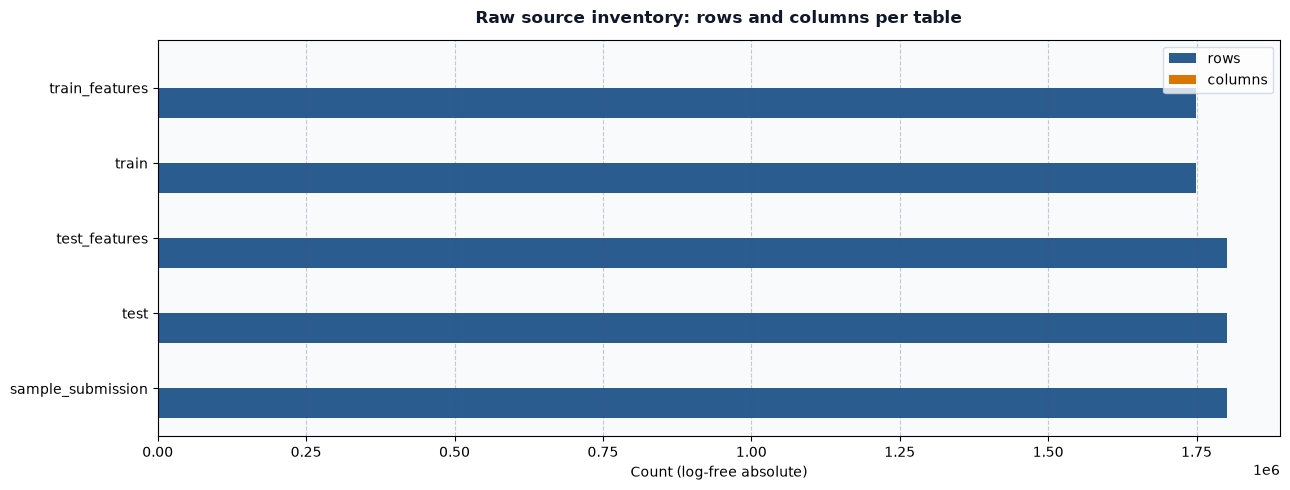

In [1]:
from IPython import get_ipython

_ip = get_ipython()
if _ip is not None:
    _ip.enable_matplotlib("inline")

import json
from pathlib import Path

import polars as pl
from IPython.display import Markdown, display

from project.data.load import scan_all_raw_tables
from project.data.validate import compute_file_sha256
from project.paths import ProjectPaths

paths = ProjectPaths.resolve(start=Path.cwd())
raw_tables = scan_all_raw_tables(paths)
lineage_path = paths.lineage_dir / 'row_lineage.json'
train_joined_path = paths.prepared_dir / 'train_joined.parquet'
test_joined_path = paths.prepared_dir / 'test_joined.parquet'
split_path = paths.splits_dir / 'building_folds_repeated.parquet'
split_metadata_path = paths.splits_dir / 'split_metadata_repeated.json'
shift_json_path = paths.shift_dir / 'adversarial_validation.json'
domain_oof_path = paths.shift_dir / 'domain_oof.parquet'
importance_path = paths.shift_dir / 'fold_averaged_importance.csv'
artifacts = {'join lineage': lineage_path, 'train join': train_joined_path,
            'test join': test_joined_path, 'building manifest': split_path,
            'split metadata': split_metadata_path, 'domain summary': shift_json_path,
            'domain OOF': domain_oof_path, 'fold importance': importance_path}
missing_artifacts = [name for name, path in artifacts.items() if not path.is_file()]
if missing_artifacts:
    raise FileNotFoundError(f'Required project artifacts are missing: {missing_artifacts}')
lineage = json.loads(lineage_path.read_text(encoding='utf-8'))
raw_schemas = {name: frame.collect_schema() for name, frame in raw_tables.items()}
train_joined = pl.scan_parquet(train_joined_path)
test_joined = pl.scan_parquet(test_joined_path)
train_schema = train_joined.collect_schema()
test_schema = test_joined.collect_schema()
raw_metadata = lineage.get('raw_file_metadata', {})
source_inventory = pl.DataFrame([
    {'source': name, 'rows_from_lineage': raw_metadata.get(f'{name}.csv', {}).get('rows'),
     'column_count': len(schema),
     'has_building_time_key': {'building_id', 'timestamp'}.issubset(schema.names()),
     'has_row_id': 'row_id' in schema, 'has_target': 'anomaly' in schema,
     'gte_family_count': sum(column.startswith('gte_') for column in schema.names())}
    for name, schema in raw_schemas.items()
]).sort('source')
display(source_inventory)

import matplotlib.pyplot as plt

from project.notebook_charts import (
    plot_comparative_count_bars,
    plot_domain_auc_dotchart,
    plot_feature_gate_bars,
    plot_fold_composition,
    plot_horizontal_missingness,
    render_integrity_tiles,
)


def show_figure(figure) -> None:
    display(figure)
    plt.close(figure)

show_figure(plot_comparative_count_bars(
    {row['source']: {'rows': int(row['rows_from_lineage'] or 0),
                     'columns': int(row['column_count'])}
     for row in source_inventory.to_dicts()},
    'Raw source inventory: rows and columns per table',
    xlabel='Count (log-free absolute)'))


**Observation:** The inventory reflects current raw schemas and preparation lineage.

**Interpretation:** Schema presence establishes shape, not prediction-time validity or feature provenance.

**Action:** Keep source files unchanged and use the join and availability checks below before modeling decisions.

## Join and data integrity

Training joins use `(building_id, timestamp)` and test joins use `row_id`; test order must match the sample file. Preparation lineage records unique keys, one-to-one joins, equality of duplicate `meter_reading` and training-target copies, building separation, and sample order. Current persisted Parquet artifacts are checked with compact streaming diagnostics.

**Purpose:** Verify persisted join assertions, key uniqueness, building disjointness, row totals, and sample order without displaying joined rows.

check,observed,status
str,i64,str
"""train rows""",1749494,"""verified"""
"""test rows""",1800567,"""verified"""
"""duplicate train keys""",0,"""verified"""
"""duplicate test keys""",0,"""verified"""
"""overlapping buildings""",0,"""verified"""
"""test/sample order mismatches""",0,"""verified"""
"""train feature columns""",57,"""verified"""
"""test feature columns""",57,"""verified"""


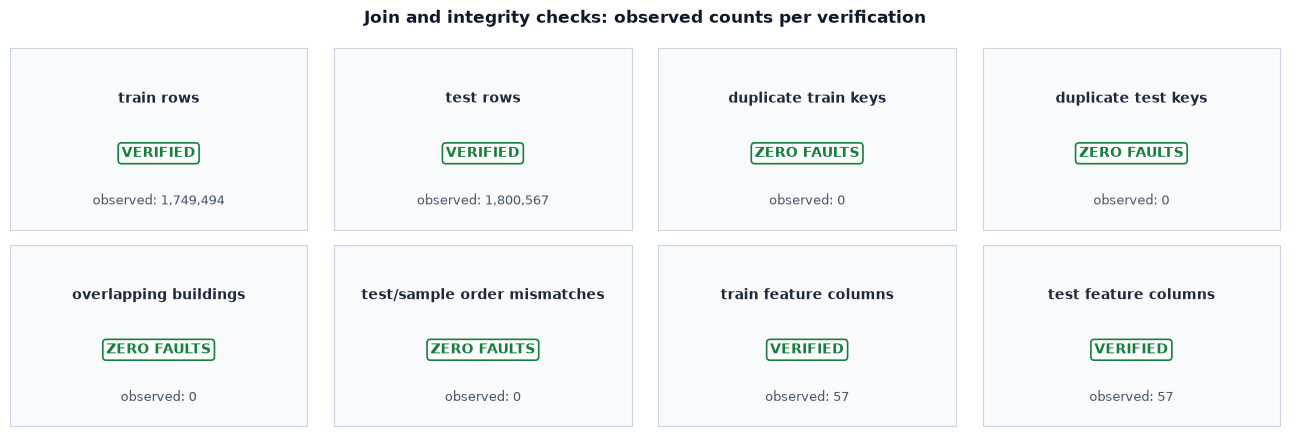

In [2]:
def duplicate_key_count(frame: pl.LazyFrame, keys: list[str]) -> int:
    return int(frame.group_by(keys).len().filter(pl.col('len') > 1)
               .select(pl.len()).collect(engine='streaming').item())

checks = lineage.get('validations', {})
required_checks = ('unique_keys_validated', 'one_to_one_joins_validated',
                  'duplicate_copy_equality_validated', 'sample_submission_order_preserved')
failed_checks = [name for name in required_checks if checks.get(name) is not True]
if checks.get('train_test_building_overlap') != 0:
    failed_checks.append('train_test_building_overlap')
if failed_checks:
    raise ValueError(f'Persisted join checks failed: {failed_checks}')
train_rows = int(train_joined.select(pl.len()).collect(engine='streaming').item())
test_rows = int(test_joined.select(pl.len()).collect(engine='streaming').item())
train_duplicate_keys = duplicate_key_count(train_joined, ['building_id', 'timestamp'])
test_duplicate_keys = duplicate_key_count(test_joined, ['row_id'])
building_overlap = int(train_joined.select('building_id').unique()
    .join(test_joined.select('building_id').unique(), on='building_id', how='inner')
    .select(pl.len()).collect(engine='streaming').item())
test_order = test_joined.select('row_id').with_row_index('_position')
sample_order = raw_tables['sample_submission'].select('row_id').with_row_index('_position')
order_mismatches = int(test_order.join(sample_order, on='_position', suffix='_sample')
    .filter(pl.col('row_id') != pl.col('row_id_sample'))
    .select(pl.len()).collect(engine='streaming').item())
if train_duplicate_keys or test_duplicate_keys or building_overlap or order_mismatches:
    raise ValueError('Current prepared joins violate a key, building, or ordering invariant')
if 'anomaly' not in train_schema or 'anomaly' in test_schema:
    raise ValueError('Target must be present in training and absent from test')
join_audit = pl.DataFrame([
    {'check': 'train rows', 'observed': train_rows, 'status': 'verified'},
    {'check': 'test rows', 'observed': test_rows, 'status': 'verified'},
    {'check': 'duplicate train keys', 'observed': train_duplicate_keys, 'status': 'verified'},
    {'check': 'duplicate test keys', 'observed': test_duplicate_keys, 'status': 'verified'},
    {'check': 'overlapping buildings', 'observed': building_overlap, 'status': 'verified'},
    {'check': 'test/sample order mismatches', 'observed': order_mismatches, 'status': 'verified'},
    {'check': 'train feature columns', 'observed': len(train_schema), 'status': 'verified'},
    {'check': 'test feature columns', 'observed': len(test_schema), 'status': 'verified'}
])
display(join_audit)

show_figure(render_integrity_tiles(
    [{'header': row['check'],
      'status': 'ZERO FAULTS' if row['observed'] == 0 else 'VERIFIED',
      'meta': f"observed: {row['observed']:,}"}
     for row in join_audit.to_dicts()],
    'Join and integrity checks: observed counts per verification'))


**Observation:** The table reports current join and key diagnostics; duplicate-copy equality comes from validated preparation lineage.

**Interpretation:** A passing join contract supports row alignment but does not prove every joined feature is safe at scoring time.

**Action:** Treat any failed invariant as a data-preparation blocker before interpreting model comparisons.

## Target and data quality

### Target support and feature quality

Target support is summarized from the current training join. Feature missingness is reported overall and by building and calendar month. True constants and highly concentrated quasi-constants are diagnostic flags only: a constant may be removed later only by a training-fold-fitted mask, while a quasi-constant requires a cross-validation ablation. The concentration cutoff is a review heuristic, not a learned preprocessing rule.

Anomalous labels and unusual meter readings are retained as possible signal. No observation is silently deleted, winsorized, or capped here.

**Purpose:** Summarize current target prevalence, feature missingness, distinct values, concentration flags, and building/month missingness ranges.

anomaly,rows,row_share
i64,u32,f64
0,1712198,0.978682
1,37296,0.021318


feature,missing_rate,max_building_missing_rate,max_month_missing_rate,non_null_unique_count,dominant_non_null_share,status
str,f64,f64,f64,i64,f64,str
"""meter_reading""",0.061534,0.615893,0.106471,191681,0.0,"""variable"""
"""site_id""",0.0,0.0,0.0,14,0.260234,"""variable"""
"""primary_use""",0.0,0.0,0.0,12,0.400567,"""variable"""
"""square_feet""",0.0,0.0,0.0,200,0.005021,"""variable"""
"""year_built""",0.0,0.0,0.0,32,0.663678,"""variable"""
…,…,…,…,…,…,…
"""sea_level_pressure""",0.0,0.0,0.0,710,0.135644,"""variable"""
"""wind_direction""",0.0,0.0,0.0,44,0.125105,"""variable"""
"""wind_speed""",0.0,0.0,0.0,59,0.125222,"""variable"""


feature,missing_rate,max_building_missing_rate,max_month_missing_rate,non_null_unique_count,dominant_non_null_share,status
str,f64,f64,f64,i64,f64,str
"""gte_meter""",0.0,0.0,0.0,1,1.0,"""true constant"""
"""year""",0.0,0.0,0.0,1,1.0,"""true constant"""


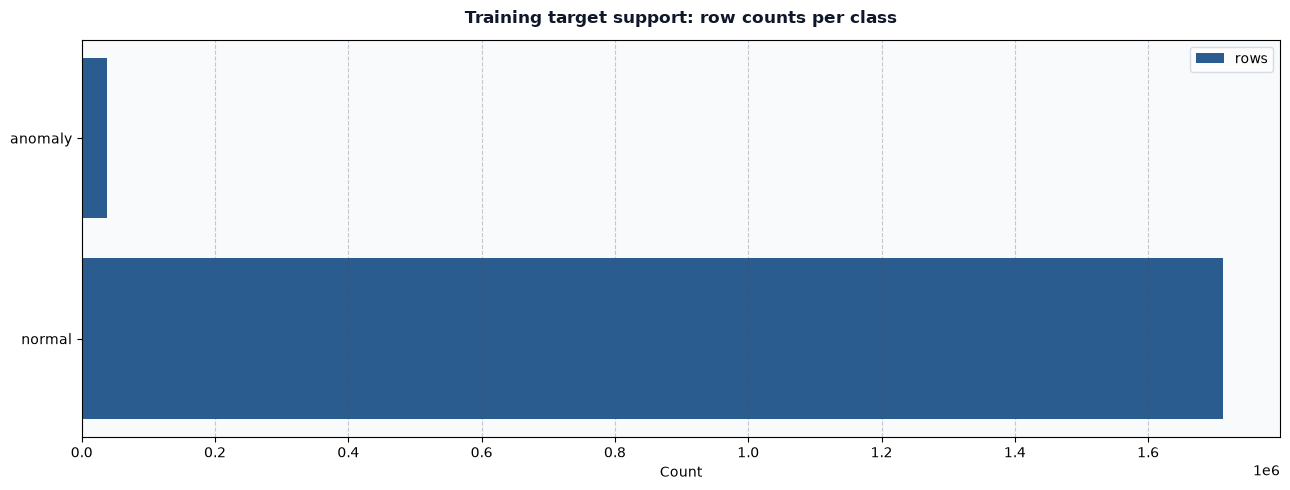

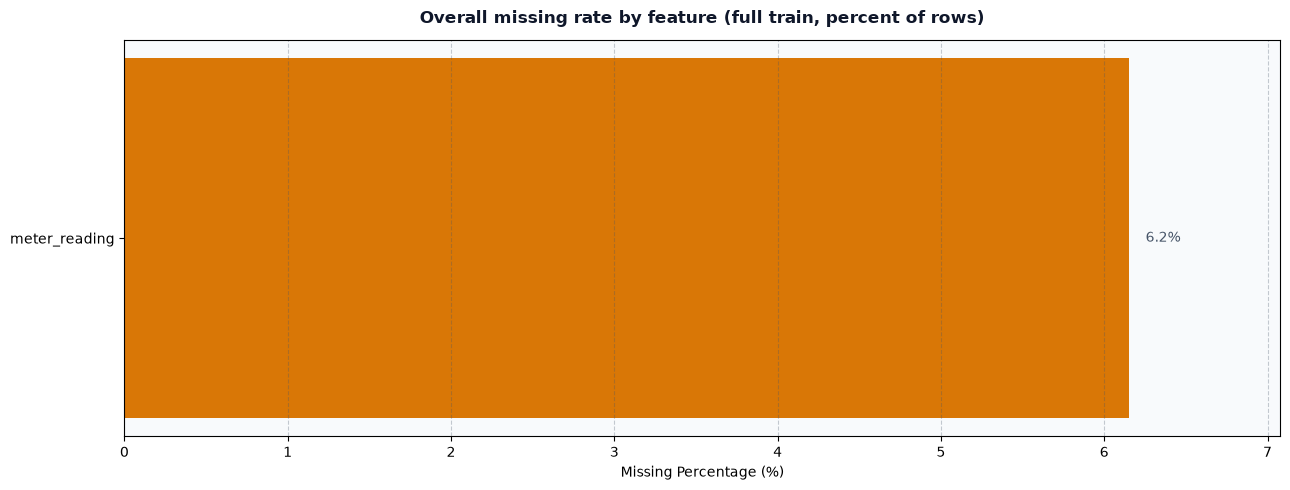

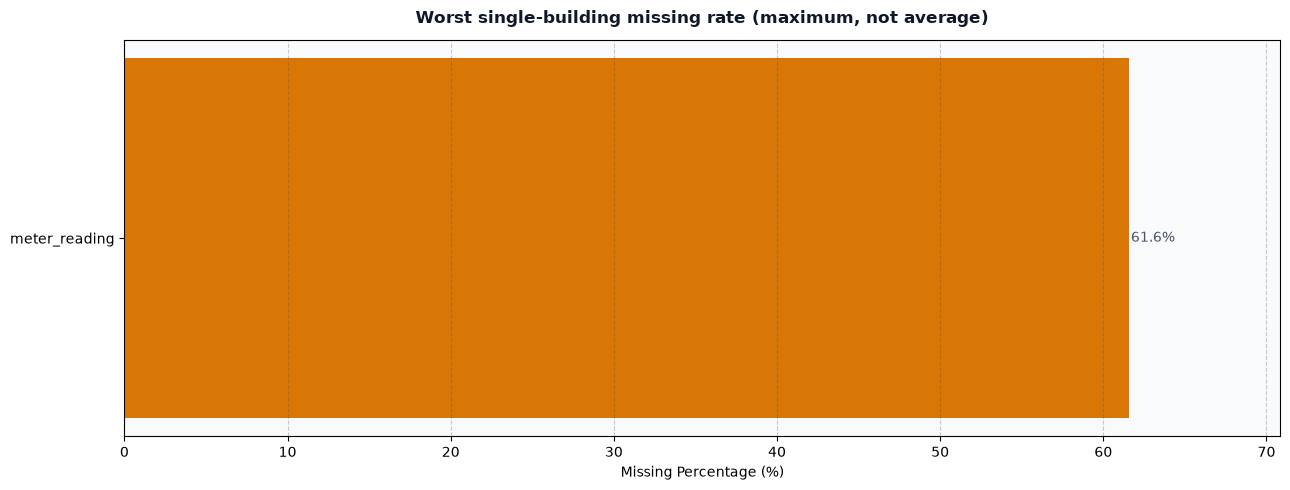

In [3]:
target_summary = train_joined.group_by('anomaly').agg(pl.len().alias('rows'))
target_summary = target_summary.sort('anomaly').collect(engine='streaming')
if set(target_summary.get_column('anomaly').to_list()) != {0, 1}:
    raise ValueError('Training target support must contain both binary classes')
target_summary = target_summary.with_columns((pl.col('rows') / pl.col('rows').sum()).alias('row_share'))
display(target_summary)
excluded = {'building_id', 'timestamp', 'row_id', 'anomaly'}
feature_columns = [name for name in train_schema.names() if name not in excluded]
if not feature_columns:
    raise ValueError('No feature columns remain after excluding keys and target')
quasi_constant_cutoff = 0.995
quality_expr = []
for feature in feature_columns:
    value = pl.col(feature)
    if train_schema[feature].is_float():
        value = value.fill_nan(None)
    mode = value.mode().first()
    quality_expr.extend([value.is_null().mean().alias(f'{feature}__missing'),
                         value.drop_nulls().n_unique().alias(f'{feature}__unique'),
                         ((value == mode).sum() / value.count()).alias(f'{feature}__dominant')])
quality_values = train_joined.select(quality_expr).collect(engine='streaming').row(0, named=True)
def missing_by_group(grouped: pl.LazyFrame, group: str) -> dict[str, object]:
    rates = [(pl.col(c).fill_nan(None) if train_schema[c].is_float() else pl.col(c))
             .is_null().mean().alias(c) for c in feature_columns]
    values = grouped.group_by(group).agg(rates).select([pl.col(c).max().alias(c) for c in feature_columns])
    return values.collect(engine='streaming').row(0, named=True)
building_missing = missing_by_group(train_joined, 'building_id')
monthly_missing = missing_by_group(train_joined.with_columns(
    pl.col('timestamp').dt.truncate('1mo').alias('_month')), '_month')
quality_rows = []
for feature in feature_columns:
    unique_count = int(quality_values[f'{feature}__unique'])
    dominant = quality_values[f'{feature}__dominant']
    status = ('all-missing' if unique_count == 0 else 'true constant' if unique_count == 1
              else 'quasi-constant' if dominant is not None and dominant >= quasi_constant_cutoff
              else 'variable')
    quality_rows.append({'feature': feature, 'missing_rate': quality_values[f'{feature}__missing'],
        'max_building_missing_rate': building_missing[feature],
        'max_month_missing_rate': monthly_missing[feature],
        'non_null_unique_count': unique_count, 'dominant_non_null_share': dominant, 'status': status})
feature_quality = pl.DataFrame(quality_rows)
display(feature_quality.sort('missing_rate', descending=True).head(15))
display(feature_quality.filter(pl.col('status').is_in(
    ['true constant', 'quasi-constant', 'all-missing'])).sort(['status', 'feature']))

show_figure(plot_comparative_count_bars(
    {('anomaly' if row['anomaly'] == 1 else 'normal'): {'rows': int(row['rows'])}
     for row in target_summary.to_dicts()},
    'Training target support: row counts per class'))

missing_top = (feature_quality.filter(pl.col('missing_rate') > 0)
               .sort('missing_rate', descending=True).head(10))
show_figure(plot_horizontal_missingness(
    {row['feature']: float(row['missing_rate']) * 100 for row in missing_top.to_dicts()},
    'Overall missing rate by feature (full train, percent of rows)'))
show_figure(plot_horizontal_missingness(
    {row['feature']: float(row['max_building_missing_rate']) * 100 for row in missing_top.to_dicts()},
    'Worst single-building missing rate (maximum, not average)'))


**Observation:** The tables show current class support, missingness ranges, and feature-concentration flags.

**Interpretation:** Dataset-wide constant diagnostics do not authorize dropping a column from a validation fold; missingness and unusual meter values may carry signal.

**Action:** Preserve anomalous rows. Defer imputation, feature removal, and outlier treatment to explicitly compared, fold-local experiments.

## Outlier analysis

### Development partition outlier audit

This audit profiles extreme values, spread statistics, and anomalous patterns within the development partition (excluding vault holdout buildings) using the frozen building split manifest. All evaluations remain strictly non-destructive: no observation is trimmed, clipped, winsorized, or deleted. In rare-event anomaly detection, extreme consumption values may represent candidate target signal or plausible high-load events rather than demonstrated data defects.

Eligible numeric columns exclude keys (`building_id`, `row_id`, `timestamp`), target (`anomaly`), and unverified `gte_*` feature families. Findings are derived directly from the development split to prevent leakage from vault holdout buildings or post-split transformations.

### Spread statistics and degenerate dispersion bounds

Univariate outlier flagging relies on non-parametric spread metrics, specifically Interquartile Range (IQR) and Median Absolute Deviation (MAD). When a building series exhibits constant or near-constant readings (where IQR = 0 or MAD = 0), spread-based fences are mathematically unavailable or degenerate. Fences cannot divide by zero or collapse to a single point; such cases require explicit fallback handling in downstream candidate pipelines rather than silent failure.

Furthermore, statistical outlier flags are exploratory screening indicators, not confirmed data errors, sensor failures, or causal detectors. Building energy consumption varies with facility scale, weather patterns, and operational occupancy regimes. A reading that appears extreme across the entire portfolio may be routine for a large healthcare facility, whereas an ordinary commercial load would be an extreme surge for an unconditioned storage unit. Relative within-building fences distinguish local deviations from global consumption scale.

**Purpose:** Execute development-partition outlier profiling using the frozen split manifest, extracting robust distribution metrics, class summaries, building summaries, temporal aggregates, and a bounded stratified plot sample.

In [4]:
from project.data.outlier_audit import build_outlier_audit


def validate_repeated_manifest(manifest, metadata, original=None):
    required = {'repeat', 'seed', 'building_id', 'split', 'fold', 'row_count', 'anomaly_count', 'normal_count'}
    if not required.issubset(manifest.columns):
        raise ValueError('Repeated manifest lacks assignment or support columns')
    if (metadata.get('repeats'), metadata.get('n_dev_folds'), metadata.get('split_seeds')) != (3, 4, [42, 43, 44]):
        raise ValueError('Expected the predeclared 4-fold x 3-repeat contract')
    if manifest.height != 600 or manifest.select(['repeat', 'building_id']).is_duplicated().any():
        raise ValueError('Expected 600 unique (repeat, building_id) assignments')
    if any(manifest[c].null_count() for c in required - {'fold'}):
        raise ValueError('Assignment and support fields must be non-null')
    if set(manifest['repeat']) != {0, 1, 2}:
        raise ValueError('Expected repeats 0, 1, 2')
    vault_ids = set(metadata.get('vault_building_ids', []))
    if len(vault_ids) != 40:
        raise ValueError('Vault metadata must specify exactly 40 fixed vault buildings')
    if original is not None:
        if original.height != 200 or original['building_id'].n_unique() != 200:
            raise ValueError('Original manifest must cover 200 unique buildings')
        old_vault = set(original.filter(pl.col('split') == 'vault')['building_id'])
        if len(old_vault) != 40 or old_vault != vault_ids:
            raise ValueError('Vault metadata differs from the original fixed vault')
        support = ['building_id', 'split', 'row_count', 'anomaly_count', 'normal_count']
        support += [c for c in ('anomaly_prevalence',) if c in original.columns]
    signatures = set()
    for repeat, seed in enumerate(metadata['split_seeds']):
        part = manifest.filter(pl.col('repeat') == repeat)
        if part.height != 200 or set(part['seed']) != {seed}:
            raise ValueError('Per-repeat population or split seed differs')
        if original is not None and not part.select(support).sort('building_id').equals(original.select(support).sort('building_id')):
            raise ValueError('Fixed population, vault, or support changed across repeats')
        vault = part.filter(pl.col('split') == 'vault')
        dev = part.filter(pl.col('split') == 'dev')
        if vault['fold'].null_count() != 40 or dev.height != 160 or dev['fold'].null_count() or set(dev['fold']) != {0, 1, 2, 3}:
            raise ValueError('Invalid fixed vault or development fold assignment')
        members = [set(dev.filter(pl.col('fold') == f)['building_id']) for f in range(4)]
        if any(len(group) != 40 for group in members):
            raise ValueError('Each development fold must contain 40 buildings')
        partitions = members + [set(vault['building_id'])]
        if any(left & right for i, left in enumerate(partitions) for right in partitions[i + 1:]):
            raise ValueError('Groups overlap within a repeat')
        signature = frozenset(frozenset(group) for group in members)
        if signature in signatures:
            raise ValueError('Repeated partitions are copied or merely fold-relabeled')
        signatures.add(signature)
    summary = (manifest.group_by(['repeat', 'seed', 'split', 'fold'])
        .agg(pl.len().alias('buildings'), pl.col('row_count').sum().alias('rows'),
             pl.col('anomaly_count').sum().alias('anomaly_rows'), pl.col('normal_count').sum().alias('normal_rows'))
        .sort(['repeat', 'split', 'fold'], nulls_last=True))
    if summary.filter((pl.col('anomaly_rows') <= 0) | (pl.col('normal_rows') <= 0)).height:
        raise ValueError('Every partition must retain both target classes')
    return summary

# Validate persisted manifest hash before building audit
split_meta = json.loads(split_metadata_path.read_text(encoding='utf-8'))
expected_manifest_hash = split_meta.get('artifacts', {}).get('building_folds_sha256')
actual_manifest_hash = compute_file_sha256(split_path)
if actual_manifest_hash != expected_manifest_hash:
    raise ValueError(f'Manifest hash mismatch: {actual_manifest_hash} != {expected_manifest_hash}')
if split_meta.get('family_sha256') != actual_manifest_hash:
    raise ValueError('Repeated family hash differs from master manifest')
original_split_path = paths.splits_dir / 'building_folds.parquet'
original_manifest = pl.read_parquet(original_split_path) if original_split_path.exists() else None
split_manifest = pl.read_parquet(split_path)
partition_support = validate_repeated_manifest(split_manifest, split_meta, original_manifest)
outlier_manifest = split_manifest.filter(pl.col('repeat') == 0).drop(['repeat', 'seed'])

# Exclude keys, target, and unverified gte_* feature families
excluded_outlier_keys = {'building_id', 'row_id', 'anomaly', 'timestamp'}
eligible_numeric_features = [
    col
    for col, dtype in train_schema.items()
    if dtype.is_numeric()
    and col not in excluded_outlier_keys
    and not col.startswith('gte_')
]

outlier_audit = build_outlier_audit(
    frame=train_joined,
    manifest=outlier_manifest,
    numeric_columns=eligible_numeric_features,
    sample_limit=12000,
)

scope_df = outlier_audit['scope']
numeric_profile = outlier_audit['numeric_profile']
meter_by_class = outlier_audit['meter_by_class']
meter_by_building = outlier_audit['meter_by_building']
meter_by_month = outlier_audit['meter_by_month']
plot_sample = outlier_audit['plot_sample']

display(scope_df)
display(meter_by_class)

# Explicit compact meter_reading profile showing all quantiles and diagnostic counts
meter_profile = numeric_profile.filter(pl.col('feature') == 'meter_reading').select([
    'feature', 'rows', 'missing_count', 'nan_count', 'nonfinite_count', 'finite_count',
    'zero_count', 'negative_count', 'min', 'q001', 'q01', 'q25', 'median', 'q75',
    'q99', 'q999', 'max', 'iqr', 'mad',
])
display(meter_profile)

# Other numeric features summary overview
other_numeric = numeric_profile.filter(pl.col('feature') != 'meter_reading').select([
    'feature', 'missing_count', 'finite_count', 'zero_count', 'min', 'median', 'max', 'iqr', 'mad',
]).head(8)
display(other_numeric)

development_rows,development_buildings,sample_rows,vault_buildings_excluded
i64,i64,i64,i64
1399631,160,12000,40


anomaly,rows,finite_count,min,q01,median,q99,max,zero_count,negative_count
i64,i64,i64,f64,f64,f64,f64,f64,i64,i64
0,1369575,1285731,0.0,0.96,85.21,1558.361,6596.89,11,0
1,30056,30056,0.029,0.12,7.0415,1479.92,6238.61,0,0


feature,rows,missing_count,nan_count,nonfinite_count,finite_count,zero_count,negative_count,min,q001,q01,q25,median,q75,q99,q999,max,iqr,mad
str,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""meter_reading""",1399631,83844,0,0,1315787,11,0,0.0,0.04,0.95,26.1,84.0,193.0,1556.317,5971.62334,6596.89,166.9,66.518


feature,missing_count,finite_count,zero_count,min,median,max,iqr,mad
str,i64,i64,i64,f64,f64,f64,f64,f64
"""square_feet""",0,1399631,0,898.0,70040.0,484376.0,106681.0,47839.0
"""year_built""",0,1399631,8784,0.0,255.0,255.0,178.0,0.0
"""floor_count""",0,1399631,1059437,0.0,0.0,12.0,0.0,0.0
"""air_temperature""",0,1399631,7964,-29.9,17.0,47.2,15.2,7.4
"""cloud_coverage""",0,1399631,502692,0.0,4.0,255.0,255.0,4.0
"""dew_temperature""",0,1399631,23491,-36.0,10.0,26.1,14.7,7.2
"""precip_depth_1_hr""",0,1399631,987100,-2.0,0.0,343.0,1.0,0.0
"""sea_level_pressure""",0,1399631,0,967.2,1014.4,1045.5,11.2,5.5


### Distributional comparisons and meter reading scaling

Direct visualization of raw energy consumption is distorted by heavy right tails, zero values (inactivity or meter shutdown), and potential negative readings (sub-metering or generation artifacts). To display the complete distribution without silently discarding negative or zero values, we apply a signed logarithmic scale:

$$\text{signed\_log1p}(x) = \text{sign}(x) \cdot \ln(1 + |x|)$$

This transformation maintains continuous ordering, maps zero to zero, preserves negative magnitudes symmetrically, and compresses high-consumption spikes. Within-class density normalization is applied so that distribution shapes can be compared across normal (anomaly=0) and anomalous (anomaly=1) records. Note that the plotting sample is class-balanced (at most 12,000 finite rows), not prevalence-representative; full-population quantiles are provided in the `meter_by_class` summary table.

**Purpose:** Generate normalized histogram and boxplot comparisons of meter_reading across normal and anomaly classes using signed log1p scaling on the bounded stratified sample.

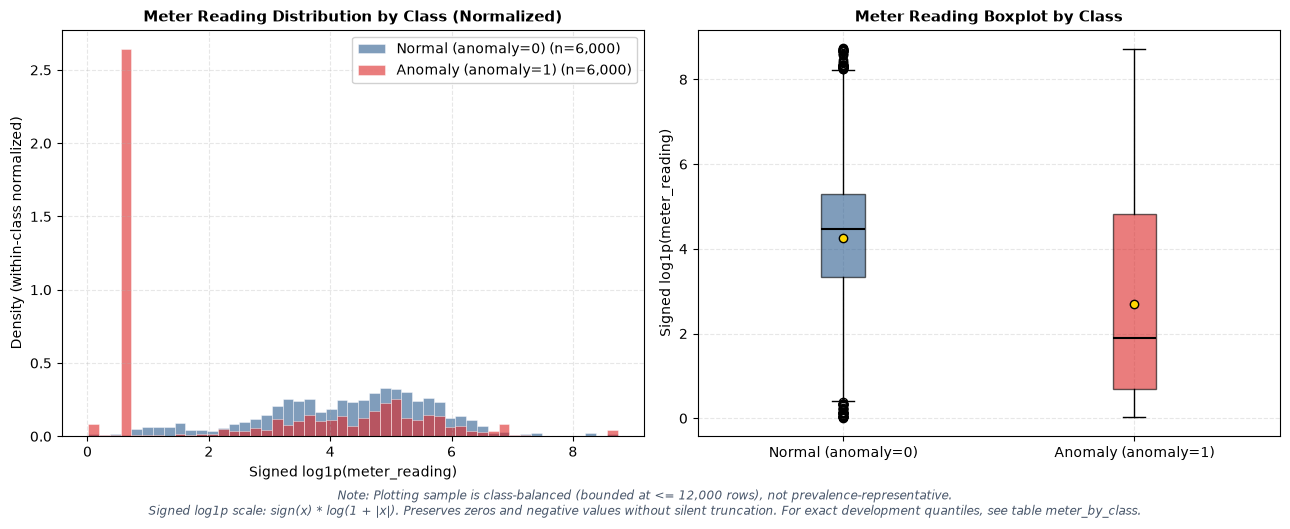

In [5]:
import numpy as np
from IPython import get_ipython

_ip = get_ipython()
if _ip is not None:
    _ip.enable_matplotlib('inline')

# Signed log1p transformation preserving zeros and negative values
def signed_log1p(values: np.ndarray) -> np.ndarray:
    return np.sign(values) * np.log1p(np.abs(values))

sample_pd = plot_sample.to_pandas()
normal_readings = sample_pd.loc[sample_pd['anomaly'] == 0, 'meter_reading'].to_numpy()
anomaly_readings = sample_pd.loc[sample_pd['anomaly'] == 1, 'meter_reading'].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=100)

# Collect available finite scaled data without fabricating absent classes
available_series = []
if len(normal_readings) > 0:
    available_series.append(('Normal (anomaly=0)', signed_log1p(normal_readings), '#2b5c8f'))
if len(anomaly_readings) > 0:
    available_series.append(('Anomaly (anomaly=1)', signed_log1p(anomaly_readings), '#dc2626'))

if available_series:
    all_vals = np.concatenate([s[1] for s in available_series])
    min_v, max_v = float(np.min(all_vals)), float(np.max(all_vals))
    bins = np.linspace(min_v - 0.5, max_v + 0.5, 50) if min_v == max_v else np.linspace(min_v, max_v, 50)

    for label, scaled_data, color in available_series:
        axes[0].hist(
            scaled_data,
            bins=bins,
            density=True,
            alpha=0.6,
            color=color,
            label=f'{label} (n={len(scaled_data):,})',
            edgecolor='white',
            linewidth=0.5,
        )

    box_labels = [s[0] for s in available_series]
    box_data = [s[1] for s in available_series]
    bp = axes[1].boxplot(
        box_data,
        tick_labels=box_labels,
        patch_artist=True,
        showmeans=True,
        medianprops={'color': 'black', 'linewidth': 1.5},
        meanprops={'marker': 'o', 'markeredgecolor': 'black', 'markerfacecolor': 'gold', 'markersize': 6},
    )
    for patch, s in zip(bp['boxes'], available_series, strict=False):
        patch.set_facecolor(s[2])
        patch.set_alpha(0.6)
else:
    axes[0].text(0.5, 0.5, 'No finite meter readings available in sample', ha='center', va='center')
    axes[1].text(0.5, 0.5, 'No finite meter readings available in sample', ha='center', va='center')

axes[0].set_title('Meter Reading Distribution by Class (Normalized)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Signed log1p(meter_reading)', fontsize=10)
axes[0].set_ylabel('Density (within-class normalized)', fontsize=10)
if available_series:
    axes[0].legend(frameon=True, facecolor='white', framealpha=0.9)
axes[0].grid(True, linestyle='--', alpha=0.3)

axes[1].set_title('Meter Reading Boxplot by Class', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Signed log1p(meter_reading)', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.3)

fig.text(
    0.5, -0.04,
    'Note: Plotting sample is class-balanced (bounded at <= 12,000 rows), not prevalence-representative.\n'
    'Signed log1p scale: sign(x) * log(1 + |x|). Preserves zeros and negative values without silent truncation. '
    'For exact development quantiles, see table meter_by_class.',
    ha='center', fontsize=8.5, color='#475569', style='italic',
)

plt.tight_layout()
plt.show()

### Building and temporal anomaly flag patterns

Building energy profiles vary widely by size, climate zone, and end use. Comparing absolute consumption values conflates facility scale with anomalous behavior. Within-building IQR and MAD fences isolate relative surges or drops compared to that specific facility's baseline. Below we inspect development-wide building anomaly rates alongside building-relative flags, followed by monthly temporal slicing to observe seasonality.

**Purpose:** Visualize development-wide building-level anomaly rates and relative IQR/MAD flag dispersion alongside monthly temporal patterns.

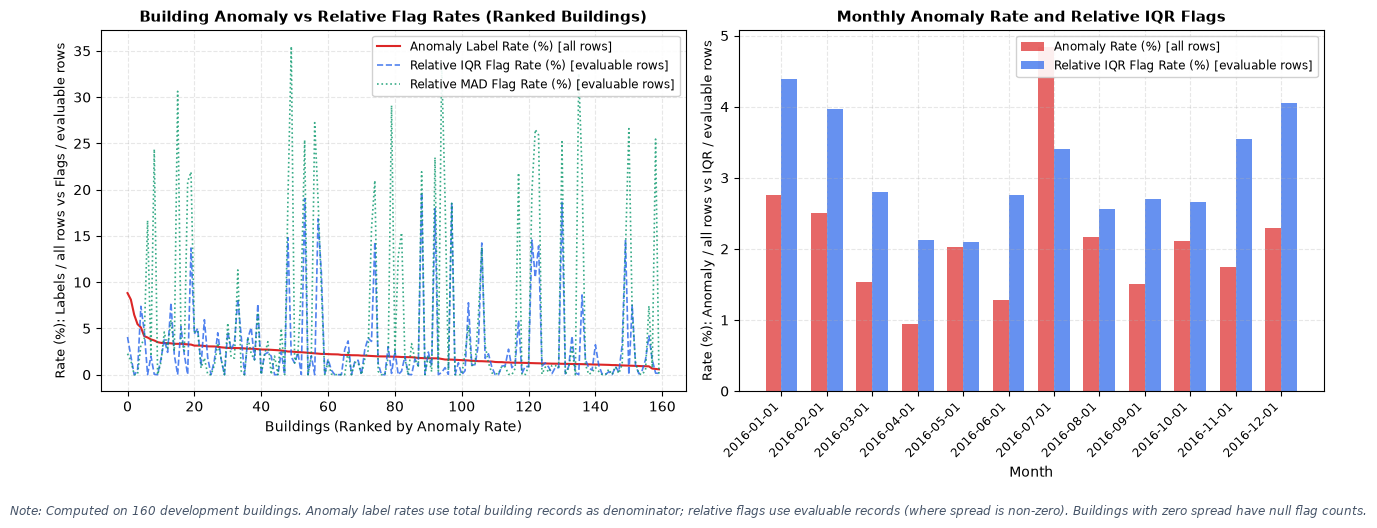

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from IPython import get_ipython

_ip = get_ipython()
if _ip is not None:
    _ip.enable_matplotlib('inline')

bldg_df = meter_by_building.to_pandas()
month_df = meter_by_month.to_pandas()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=100)

# Building-level overview: anomaly label rate across all rows vs relative flag rate across evaluable readings
bldg_df['anomaly_rate'] = bldg_df['anomaly_rows'] / bldg_df['rows']
bldg_df['iqr_flag_rate'] = np.where(
    bldg_df['iqr_evaluable_count'] > 0,
    bldg_df['iqr_flag_count'] / bldg_df['iqr_evaluable_count'],
    np.nan,
)
bldg_df['mad_flag_rate'] = np.where(
    bldg_df['mad_evaluable_count'] > 0,
    bldg_df['mad_flag_count'] / bldg_df['mad_evaluable_count'],
    np.nan,
)

sorted_bldg = bldg_df.sort_values('anomaly_rate', ascending=False).reset_index(drop=True)
x_idx = np.arange(len(sorted_bldg))

axes[0].plot(x_idx, sorted_bldg['anomaly_rate'] * 100, color='#dc2626', label='Anomaly Label Rate (%) [all rows]', linewidth=1.5)
axes[0].plot(x_idx, sorted_bldg['iqr_flag_rate'] * 100, color='#2563eb', linestyle='--', label='Relative IQR Flag Rate (%) [evaluable rows]', linewidth=1.2, alpha=0.8)
axes[0].plot(x_idx, sorted_bldg['mad_flag_rate'] * 100, color='#059669', linestyle=':', label='Relative MAD Flag Rate (%) [evaluable rows]', linewidth=1.2, alpha=0.8)
axes[0].set_title('Building Anomaly vs Relative Flag Rates (Ranked Buildings)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Buildings (Ranked by Anomaly Rate)', fontsize=10)
axes[0].set_ylabel('Rate (%): Labels / all rows vs Flags / evaluable rows', fontsize=9.5)
axes[0].legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=8.5)
axes[0].grid(True, linestyle='--', alpha=0.3)

# Monthly pattern chart: monthly anomaly rate across all rows vs relative IQR flags across evaluable readings
month_df['month_str'] = month_df['month'].astype(str)
month_df['monthly_anomaly_rate'] = month_df['anomaly_rows'] / month_df['rows'] * 100
month_df['monthly_iqr_rate'] = np.where(
    month_df['iqr_evaluable_count'] > 0,
    (month_df['iqr_flag_count'] / month_df['iqr_evaluable_count']) * 100,
    np.nan,
)

bar_x = np.arange(len(month_df))
bar_width = 0.35

axes[1].bar(bar_x - bar_width / 2, month_df['monthly_anomaly_rate'], width=bar_width, color='#dc2626', alpha=0.7, label='Anomaly Rate (%) [all rows]')
axes[1].bar(bar_x + bar_width / 2, month_df['monthly_iqr_rate'], width=bar_width, color='#2563eb', alpha=0.7, label='Relative IQR Flag Rate (%) [evaluable rows]')
axes[1].set_xticks(bar_x)
axes[1].set_xticklabels(month_df['month_str'], rotation=45, ha='right', fontsize=8.5)
axes[1].set_title('Monthly Anomaly Rate and Relative IQR Flags', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Month', fontsize=10)
axes[1].set_ylabel('Rate (%): Anomaly / all rows vs IQR / evaluable rows', fontsize=9.5)
axes[1].legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=8.5)
axes[1].grid(True, linestyle='--', alpha=0.3)

fig.text(
    0.5, -0.04,
    'Note: Computed on 160 development buildings. Anomaly label rates use total building records as denominator; '
    'relative flags use evaluable records (where spread is non-zero). Buildings with zero spread have null flag counts.',
    ha='center', fontsize=8.5, color='#475569', style='italic',
)

plt.tight_layout()
plt.show()

### Outlier decision ledger and runtime findings

The summary below synthesizes empirical evidence from the development partition audit into a runtime Observation, Interpretation, and Action (O/I/A) review and a formal decision ledger.

**Purpose:** Assemble dynamic runtime Observation, Interpretation, and Action findings and display the outlier decision ledger from development audit metrics.

In [7]:
dev_rows = int(scope_df.get_column('development_rows').item())
dev_buildings = int(scope_df.get_column('development_buildings').item())
sample_rows_count = int(scope_df.get_column('sample_rows').item())
vault_excluded = int(scope_df.get_column('vault_buildings_excluded').item())

normal_df = meter_by_class.filter(pl.col('anomaly') == 0)
anomaly_df = meter_by_class.filter(pl.col('anomaly') == 1)

normal_stats = normal_df.row(0, named=True) if normal_df.height > 0 else {}
anomaly_stats = anomaly_df.row(0, named=True) if anomaly_df.height > 0 else {}

negative_meter_total = int(normal_stats.get('negative_count', 0) + anomaly_stats.get('negative_count', 0))
zero_meter_total = int(normal_stats.get('zero_count', 0) + anomaly_stats.get('zero_count', 0))

iqr_unavailable_bldgs = int(meter_by_building.filter(~pl.col('iqr_available')).height)
mad_unavailable_bldgs = int(meter_by_building.filter(~pl.col('mad_available')).height)

neg_text = f"{negative_meter_total:,} negative readings observed" if negative_meter_total > 0 else "0 negative readings observed in the development split"
avail_text = (
    f"All {dev_buildings} development buildings have non-zero spread (0 buildings with unavailable IQR or MAD fences)."
    if iqr_unavailable_bldgs == 0 and mad_unavailable_bldgs == 0
    else f"Zero or non-finite spread makes IQR fences unavailable for {iqr_unavailable_bldgs} buildings and MAD fences unavailable for {mad_unavailable_bldgs} buildings."
)

iqr_flags_sum = meter_by_building.get_column('iqr_flag_count').drop_nulls().sum()
total_iqr_flags = int(iqr_flags_sum) if iqr_flags_sum is not None else 0

iqr_eval_sum = meter_by_building.get_column('iqr_evaluable_count').sum()
total_iqr_eval = int(iqr_eval_sum) if iqr_eval_sum is not None else 0
iqr_flag_summary = (
    f"{total_iqr_flags:,} observations ({total_iqr_flags / total_iqr_eval * 100:.2f}%) are flagged by building-relative 1.5-IQR fences"
    if total_iqr_eval > 0
    else "building-relative IQR flag rate is unavailable (0 evaluable readings with non-zero spread)"
)

normal_med_str = f"{normal_stats['median']:.3f}" if normal_stats.get('median') is not None else "N/A"
normal_max_str = f"{normal_stats['max']:.3f}" if normal_stats.get('max') is not None else "N/A"
anomaly_med_str = f"{anomaly_stats['median']:.3f}" if anomaly_stats.get('median') is not None else "N/A"
anomaly_max_str = f"{anomaly_stats['max']:.3f}" if anomaly_stats.get('max') is not None else "N/A"

oia_report = (
    f"**Observation:** The development partition audit covers {dev_rows:,} records across "
    f"{dev_buildings} buildings ({sample_rows_count:,} class-balanced sample rows, "
    f"{vault_excluded} vault buildings excluded). "
    f"Meter reading quality checks show {neg_text} and {zero_meter_total:,} zero readings. "
    f"Normal class median is {normal_med_str} (max: {normal_max_str}), "
    f"while anomaly class median is {anomaly_med_str} (max: {anomaly_max_str}). "
    f"{avail_text} Across evaluable readings, {iqr_flag_summary}.\n\n"
    f"**Interpretation:** Heavy right tails and distinct median profiles indicate potential "
    f"facility scale variations, operational schedules, seasonal patterns, or target signal. "
    f"The physical and operational causes of these patterns remain unverified; statistical outlier flags "
    f"are exploratory screening markers rather than confirmed data defects. "
    f"{zero_meter_total} zero readings observed; inactivity, shutdowns, or other causes remain unverified; zeros alone do not justify deleting records. "
    f"When a series exhibits zero dispersion, spread-based fences degenerate and require explicit fallback logic.\n\n"
    f"**Action:** Retain all raw records without deletion, trimming, or winsorization. "
    f"Treat statistical flags strictly as exploratory indicators, not error detectors. "
    f"Evaluate robust transforms (e.g. signed log1p) and fold-local relative indicators in Notebook 02."
)
display(Markdown(oia_report))

iqr_pct_str = f"{total_iqr_flags / total_iqr_eval * 100:.2f}% of evaluable records" if total_iqr_eval > 0 else "unavailable (0 evaluable)"
anomaly_rows_cnt = anomaly_stats.get('rows', 0)
anomaly_pct_str = f"{anomaly_rows_cnt / dev_rows:.2%}" if dev_rows > 0 else "N/A"

outlier_ledger = pl.DataFrame([
    {
        'topic': 'Data Retention',
        'policy': f'Preserve all {dev_rows:,} development rows intact',
        'measured_evidence': f'{zero_meter_total} zeros, {negative_meter_total} negatives; max normal {normal_max_str}, max anomaly {anomaly_max_str}; causes unresolved',
        'decision_boundary': 'No observation deleted, trimmed, or winsorized; all rows retained',
    },
    {
        'topic': 'Exploratory Screening',
        'policy': 'Building-relative flags for exploration only',
        'measured_evidence': f'{total_iqr_flags:,} IQR flags ({iqr_pct_str}); anomaly label rate {anomaly_pct_str}',
        'decision_boundary': 'Screening markers only; not ground-truth error labels or causal filters',
    },
    {
        'topic': 'Degenerate Bounds',
        'policy': 'Explicit fallback when IQR=0 or MAD=0',
        'measured_evidence': f'{dev_buildings - iqr_unavailable_bldgs}/{dev_buildings} buildings currently evaluable; pipeline requires robust fallback',
        'decision_boundary': 'Downstream pipelines must handle null flags and 0 evaluable counts without dividing by zero',
    },
    {
        'topic': 'Candidate Engineering',
        'policy': 'Defer indicator and transform features',
        'measured_evidence': f'Median divergence (normal {normal_med_str} vs anomaly {anomaly_med_str}) and heavy right tail',
        'decision_boundary': 'Evaluate raw features vs signed log1p and fold-local flags inside fixed CV folds in Notebook 02',
    },
])
display(outlier_ledger)

**Observation:** The development partition audit covers 1,399,631 records across 160 buildings (12,000 class-balanced sample rows, 40 vault buildings excluded). Meter reading quality checks show 0 negative readings observed in the development split and 11 zero readings. Normal class median is 85.210 (max: 6596.890), while anomaly class median is 7.042 (max: 6238.610). All 160 development buildings have non-zero spread (0 buildings with unavailable IQR or MAD fences). Across evaluable readings, 40,685 observations (3.09%) are flagged by building-relative 1.5-IQR fences.

**Interpretation:** Heavy right tails and distinct median profiles indicate potential facility scale variations, operational schedules, seasonal patterns, or target signal. The physical and operational causes of these patterns remain unverified; statistical outlier flags are exploratory screening markers rather than confirmed data defects. 11 zero readings observed; inactivity, shutdowns, or other causes remain unverified; zeros alone do not justify deleting records. When a series exhibits zero dispersion, spread-based fences degenerate and require explicit fallback logic.

**Action:** Retain all raw records without deletion, trimming, or winsorization. Treat statistical flags strictly as exploratory indicators, not error detectors. Evaluate robust transforms (e.g. signed log1p) and fold-local relative indicators in Notebook 02.

topic,policy,measured_evidence,decision_boundary
str,str,str,str
"""Data Retention""","""Preserve all 1,399,631 develop…","""11 zeros, 0 negatives; max nor…","""No observation deleted, trimme…"
"""Exploratory Screening""","""Building-relative flags for ex…","""40,685 IQR flags (3.09% of eva…","""Screening markers only; not gr…"
"""Degenerate Bounds""","""Explicit fallback when IQR=0 o…","""160/160 buildings currently ev…","""Downstream pipelines must hand…"
"""Candidate Engineering""","""Defer indicator and transform …","""Median divergence (normal 85.2…","""Evaluate raw features vs signe…"


## Train/test shift

### Per-building domain diagnostic

The persisted diagnostic uses one summary row per building so repeated hourly observations are not treated as independent buildings. Numeric fields are summarized by mean, median, and missingness; categorical fields by mode only. Building row count is diagnostic metadata only. Building identifiers, source fields, targets, and domain labels are not classifier predictors. This notebook reads script-produced ROC-AUC, Average Precision, LogLoss, fold summaries, null references, OOF scores, and fold-averaged importance; it does not fit a domain classifier.

For ROC-AUC values at or above 0.5, the bands `<=0.55`, `0.55–0.60`, and `>0.60` are heuristic descriptions of weak, moderate, and more material train/test distinguishability, not automatic decisions. AUC below 0.5 for the declared positive class `test=1` is reported separately as an inverse ranking that requires class/score-orientation and fold-level review; do not invert scores after observing the result. Material shift triggers validation, robustness, and monitoring review. It never authorizes test-guided feature deletion, feature selection, or production-preprocessing fitting.

**Purpose:** Read current domain-validation metrics and artifact schemas, plus compact univariate train/test shift summaries.

metric,value
str,f64
"""configuration.folds""",5.0
"""metrics.fold_mean_std.average_…",0.472989
"""metrics.fold_mean_std.average_…",0.034783
"""metrics.fold_mean_std.log_loss…",0.716909
"""metrics.fold_mean_std.log_loss…",0.013947
…,…
"""metrics.pooled_oof.log_loss""",0.716883
"""metrics.pooled_oof.roc_auc""",0.435267
"""null_baselines.average_precisi…",0.507389


artifact,rows,columns,has_fold_field
str,i64,i64,bool
"""domain_oof.parquet""",406,5,true


feature,importance_mean
str,f64
"""meter_reading__mean""",0.012086
"""gte_meter_building_id_weekday_…",0.008531
"""meter_reading__median""",0.007424
"""gte_meter_building_id_month__m…",0.006981
"""air_temperature_std_lag73__mea…",0.006314
…,…
"""square_feet__median""",0.004412
"""gte_meter_building_id_hour__me…",0.004322
"""air_temperature_std_lag73__med…",0.003832


feature,train_mean,test_mean,mean_difference,mean_difference_in_train_sd,train_median,test_median,train_missingness,test_missingness
str,f64,f64,f64,f64,f64,f64,f64,f64
"""year_built""",192.55816,195.356921,2.798762,0.031326,255.0,255.0,0.0,0.0
"""gte_site_id""",4.380949,4.402207,0.021258,0.027463,4.71,4.71,0.0,0.0
"""site_id""",7.819728,7.912157,0.092429,0.019136,9.0,9.0,0.0,0.0
"""air_temperature_std_lag73""",3.647699,3.663056,0.015356,0.012248,3.621,3.641,0.0,0.0
"""gte_meter_site_id""",4.261428,4.268292,0.006864,0.009921,4.548,4.548,0.0,0.0
…,…,…,…,…,…,…,…,…
"""air_temperature_std_lag7""",1.588481,1.593044,0.004563,0.004272,1.361,1.362,0.0,0.0
"""air_temperature_max_lag73""",22.479426,22.515292,0.035865,0.003609,23.234,23.234,0.0,0.0
"""air_temperature_max_lag7""",18.423979,18.437669,0.01369,0.001306,18.719,18.719,0.0,0.0


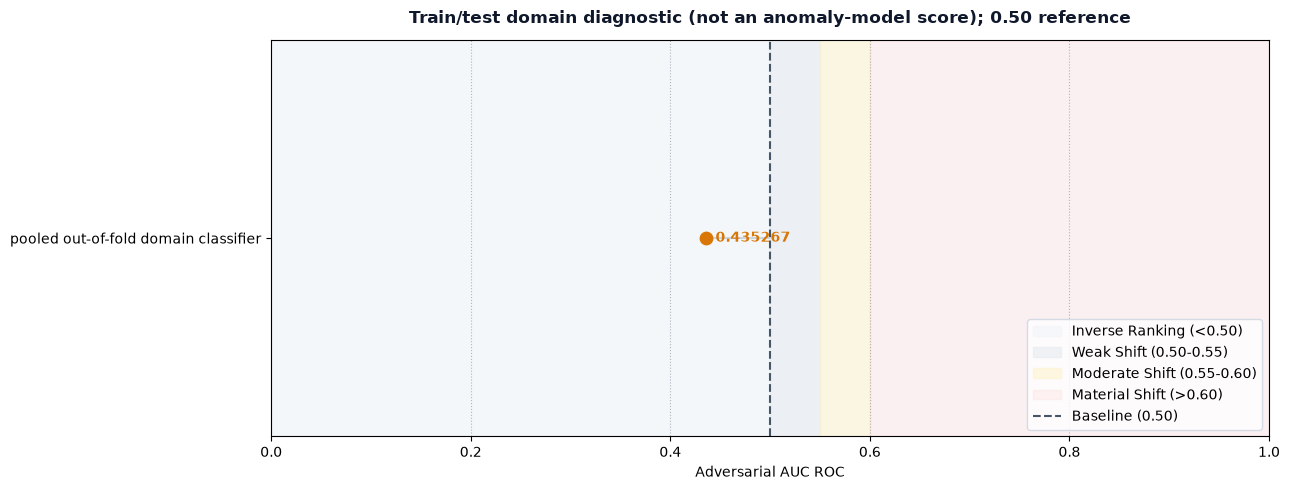

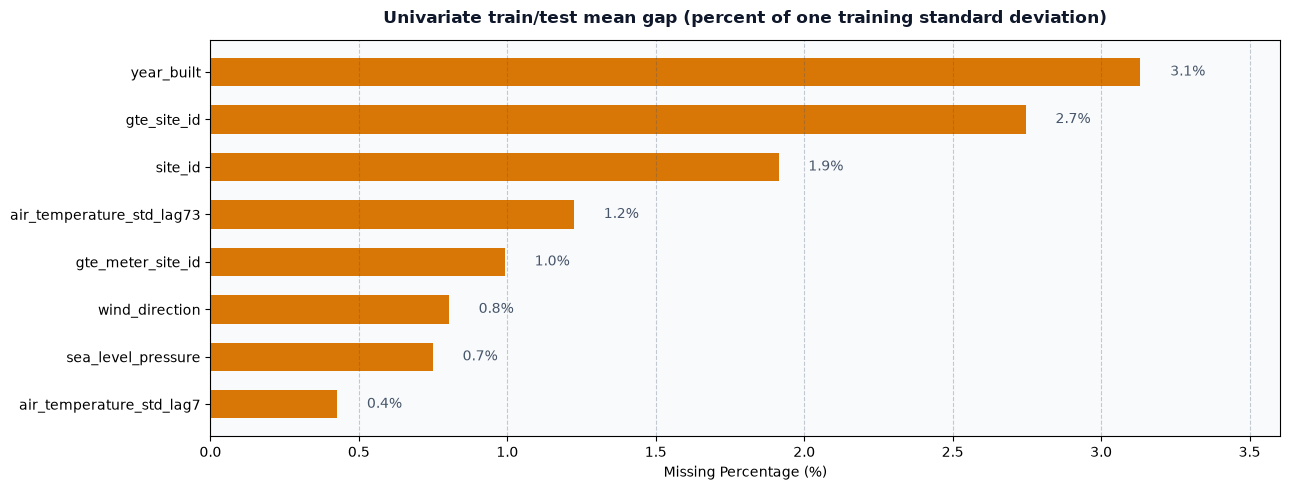

In [8]:
domain_report = json.loads(shift_json_path.read_text(encoding='utf-8'))
def validate_domain_artifact_hashes(
    report: dict[str, object], artifact_paths: dict[str, Path]
) -> None:
    if not isinstance(report, dict):
        raise TypeError('Domain validation report must be a JSON object')
    recorded_artifacts = report.get('artifacts')
    if not isinstance(recorded_artifacts, dict):
        raise TypeError('Domain report is missing its artifact hash manifest')
    for artifact_name, artifact_path in artifact_paths.items():
        artifact = recorded_artifacts.get(artifact_name)
        expected_hash = artifact.get('sha256') if isinstance(artifact, dict) else None
        if not isinstance(expected_hash, str) or not expected_hash:
            raise ValueError(
                f'Domain report is missing the SHA-256 for {artifact_name}'
            )
        if compute_file_sha256(artifact_path) != expected_hash:
            raise ValueError(
                f'Domain report has a stale hash for {artifact_name}; '
                'rerun adversarial validation'
            )

validate_domain_artifact_hashes(domain_report, {
    'input_train_parquet': train_joined_path,
    'input_test_parquet': test_joined_path,
    'domain_oof_parquet': domain_oof_path,
    'fold_averaged_importance_csv': importance_path,
})
def scalar_metrics(payload: object, prefix: str = '') -> list[dict[str, object]]:
    terms = ('auc', 'average_precision', 'log_loss', 'prevalence', 'null', 'entropy', 'fold')
    rows: list[dict[str, object]] = []
    if isinstance(payload, dict):
        for key, value in payload.items():
            name = f'{prefix}.{key}' if prefix else str(key)
            rows.extend(scalar_metrics(value, name))
    elif isinstance(payload, list):
        for index, value in enumerate(payload):
            rows.extend(scalar_metrics(value, f'{prefix}[{index}]'))
    elif (isinstance(payload, (int, float)) and not isinstance(payload, bool)
          and any(term in prefix.casefold() for term in terms)):
        rows.append({'metric': prefix, 'value': float(payload)})
    return rows
domain_metrics = pl.DataFrame(scalar_metrics(domain_report),
    schema={'metric': pl.String, 'value': pl.Float64})
display(domain_metrics.sort('metric'))
domain_oof = pl.scan_parquet(domain_oof_path)
domain_oof_schema = domain_oof.collect_schema()
domain_oof_rows = int(domain_oof.select(pl.len()).collect(engine='streaming').item())
display(pl.DataFrame([{'artifact': 'domain_oof.parquet', 'rows': domain_oof_rows,
    'columns': len(domain_oof_schema), 'has_fold_field': 'fold' in domain_oof_schema}]))
fold_importance = pl.read_csv(importance_path)
importance_column = next((c for c in ('mean_importance', 'importance_mean', 'importance',
    'fold_averaged_importance') if c in fold_importance.columns), None)
feature_name_column = next((c for c in ('feature', 'feature_name', 'column')
    if c in fold_importance.columns), None)
if importance_column and feature_name_column:
    display(fold_importance.sort(importance_column, descending=True)
        .select(feature_name_column, importance_column).head(12))
else:
    display(pl.DataFrame({'importance_artifact_columns': fold_importance.columns}))
numeric_features = [name for name in feature_columns
    if name in test_schema and train_schema[name].is_numeric()]
def numeric_summary(frame: pl.LazyFrame) -> dict[str, object]:
    expressions = []
    for feature in numeric_features:
        value = pl.col(feature)
        if train_schema[feature].is_float():
            value = value.fill_nan(None)
        expressions.extend([value.mean().alias(f'{feature}__mean'),
            value.median().alias(f'{feature}__median'), value.std().alias(f'{feature}__std'),
            value.is_null().mean().alias(f'{feature}__missing')])
    return frame.select(expressions).collect(engine='streaming').row(0, named=True)
train_numeric = numeric_summary(train_joined)
test_numeric = numeric_summary(test_joined)
shift_rows = []
for feature in numeric_features:
    train_mean, test_mean = train_numeric[f'{feature}__mean'], test_numeric[f'{feature}__mean']
    train_std = train_numeric[f'{feature}__std']
    shift_rows.append({'feature': feature, 'train_mean': train_mean, 'test_mean': test_mean,
        'mean_difference': test_mean - train_mean,
        'mean_difference_in_train_sd': (test_mean - train_mean) / train_std
            if train_std is not None and train_std > 0 else None,
        'train_median': train_numeric[f'{feature}__median'],
        'test_median': test_numeric[f'{feature}__median'],
        'train_missingness': train_numeric[f'{feature}__missing'],
        'test_missingness': test_numeric[f'{feature}__missing']})
univariate_shift = pl.DataFrame(shift_rows)
if univariate_shift.height:
    display(univariate_shift.sort('mean_difference_in_train_sd',
        descending=True, nulls_last=True).head(12))

pooled_auc_rows = [row['value'] for row in domain_metrics.to_dicts()
                   if row['metric'].casefold().endswith('pooled_oof.roc_auc')]
if pooled_auc_rows:
    show_figure(plot_domain_auc_dotchart(
        {'pooled out-of-fold domain classifier': float(pooled_auc_rows[0])},
        'Train/test domain diagnostic (not an anomaly-model score); 0.50 reference'))

shift_top = univariate_shift.sort('mean_difference_in_train_sd', descending=True,
                                  nulls_last=True).head(8)
show_figure(plot_horizontal_missingness(
    {row['feature']: abs(float(row['mean_difference_in_train_sd'] or 0.0)) * 100
     for row in shift_top.to_dicts()},
    'Univariate train/test mean gap (percent of one training standard deviation)'))


**Observation:** Persisted OOF metrics and univariate summaries describe train/test distinguishability.

**Interpretation:** The univariate comparison is row-weighted; the domain diagnostic uses building-level summaries. Differences and importance are shift evidence only, not feature-selection criteria. Test predictors must not fit production preprocessing.

**Action:** Treat AUC below 0.5 as an inverse-ranking signal requiring orientation and fold-level review; do not invert it after observing results. For a positive-direction score in the material heuristic band, review validation design, robustness coverage, and monitoring. Do not use test predictors to select features.

## Feature availability and leakage

A feature is eligible for a later predictor contract only after its generating source, target dependence, aggregation scope, and availability at the observed-hour prediction cutoff are verified. `building_id` is a grouping key only and is not a raw predictor. `row_id`, target, fold/domain indicators, and source metadata are not predictors. Future-derived, target-derived, and unverified features remain excluded until their lineage is demonstrated.

Every current `gte_*` field is `pending/blocked` because no verified provenance record is available in the current feature metadata. The persisted domain-shift report may include these values strictly for shift diagnosis; they remain blocked as production predictors and are not selected from test results. This status changes only when source, target dependence, aggregation boundary, and time availability are verified. Lag and building-aggregate fields also require prediction-time and fold-boundary review; their names alone do not establish safety.

**Purpose:** Inventory discovered `gte_*` fields and show the identifier, target, and metadata exclusion policy.

feature,provenance_status,production_predictor_eligible,required_evidence
str,str,bool,str
"""gte_hour""","""pending/blocked""",false,"""source, target dependence, agg…"
"""gte_weekday""","""pending/blocked""",false,"""source, target dependence, agg…"
"""gte_month""","""pending/blocked""",false,"""source, target dependence, agg…"
"""gte_building_id""","""pending/blocked""",false,"""source, target dependence, agg…"
"""gte_primary_use""","""pending/blocked""",false,"""source, target dependence, agg…"
…,…,…,…
"""gte_meter_primary_use""","""pending/blocked""",false,"""source, target dependence, agg…"
"""gte_meter_site_id""","""pending/blocked""",false,"""source, target dependence, agg…"
"""gte_meter_building_id_hour""","""pending/blocked""",false,"""source, target dependence, agg…"


field,role,production_predictor_policy
str,str,str
"""building_id""","""grouping key only""","""exclude raw identifier"""
"""row_id""","""row alignment key""","""exclude"""
"""anomaly""","""training target""","""exclude from X"""
"""fold/domain/source metadata""","""validation or lineage metadata""","""exclude from X"""
"""gte_*""","""unverified feature family""","""pending/blocked"""


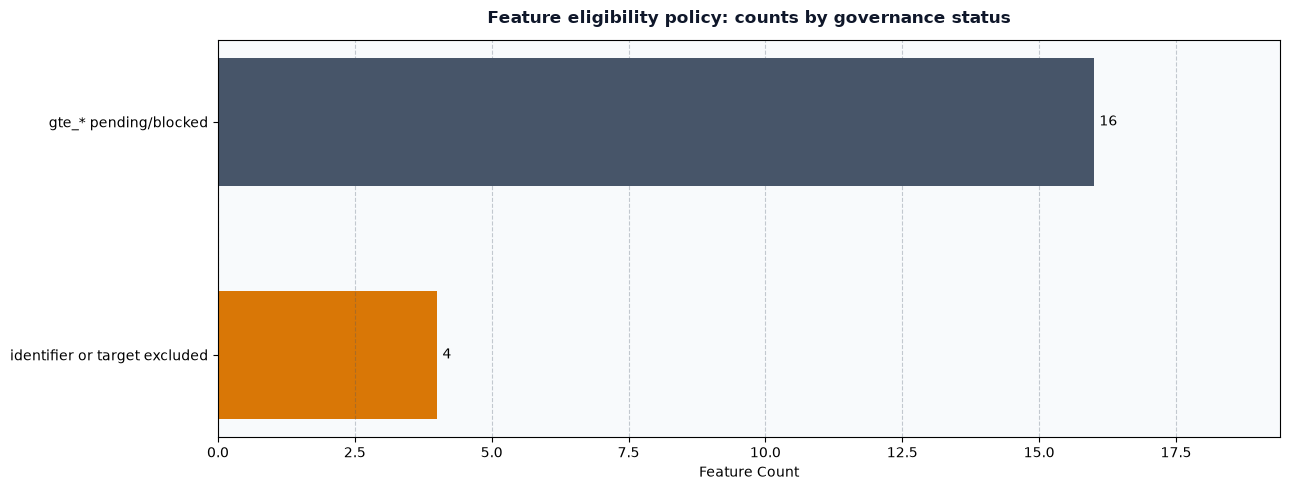

In [9]:
gte_columns = [name for name in train_schema.names() if name.startswith('gte_')]
gte_audit = pl.DataFrame([
    {'feature': feature, 'provenance_status': 'pending/blocked',
     'production_predictor_eligible': False,
     'required_evidence': 'source, target dependence, aggregation scope, prediction-time availability'}
    for feature in gte_columns
], schema={'feature': pl.String, 'provenance_status': pl.String,
          'production_predictor_eligible': pl.Boolean, 'required_evidence': pl.String})
display(gte_audit)
feature_policy = pl.DataFrame([
    {'field': 'building_id', 'role': 'grouping key only', 'production_predictor_policy': 'exclude raw identifier'},
    {'field': 'row_id', 'role': 'row alignment key', 'production_predictor_policy': 'exclude'},
    {'field': 'anomaly', 'role': 'training target', 'production_predictor_policy': 'exclude from X'},
    {'field': 'fold/domain/source metadata', 'role': 'validation or lineage metadata', 'production_predictor_policy': 'exclude from X'},
    {'field': 'gte_*', 'role': 'unverified feature family', 'production_predictor_policy': 'pending/blocked'}
])
display(feature_policy)

gte_pending = int(gte_audit.height)
show_figure(plot_feature_gate_bars(
    {'gte_* pending/blocked': gte_pending,
     'identifier or target excluded': int(feature_policy.height) - 1},
    'Feature eligibility policy: counts by governance status'))


**Observation:** The current schema contains the fields listed above; the `gte_*` status is explicit and conservative.

**Interpretation:** Availability cannot be inferred from a feature name or train/test distribution comparison.

**Action:** Exclude unverified families and identifiers from model inputs until fold-safe provenance and availability evidence is recorded.

## Persisted split decision

The training assignment is loaded from `outputs/splits/building_folds_repeated.parquet`; this notebook does not create or reshuffle a split. One manifest row represents one training building. The manifest must cover current training buildings exactly, remain disjoint from test buildings, and retain positive and negative support within each persisted partition. Its artifact hash is checked against the accompanying split metadata.

**Purpose:** Verify the persisted manifest hash, building membership, group separation, and class support by partition.

manifest_buildings,train_buildings_covered,test_buildings_disjoint,repeats,split_seeds,manifest_sha256_prefix
i64,i64,bool,i64,str,str
200,200,true,3,"""[42, 43, 44]""","""4b3433d604d7"""


split,fold,buildings,rows,anomaly_rows,normal_rows
str,i64,u32,i64,i64,i64
"""dev""",0,40,350908,7313,343595
"""dev""",1,40,350467,7518,342949
"""dev""",2,40,348223,7644,340579
"""dev""",3,40,350033,7581,342452
"""vault""",null,40,349863,7240,342623


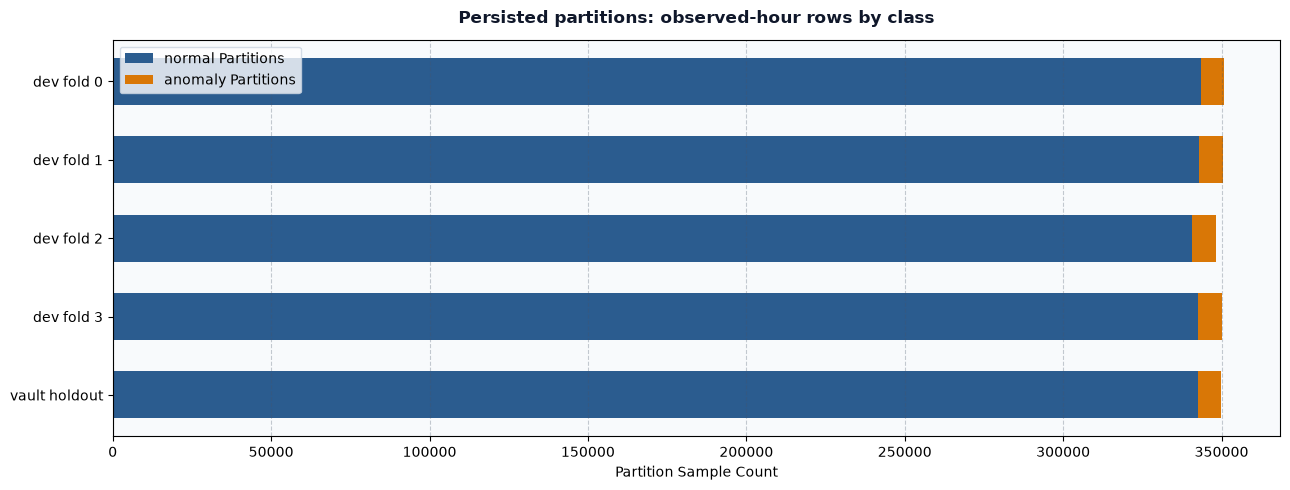

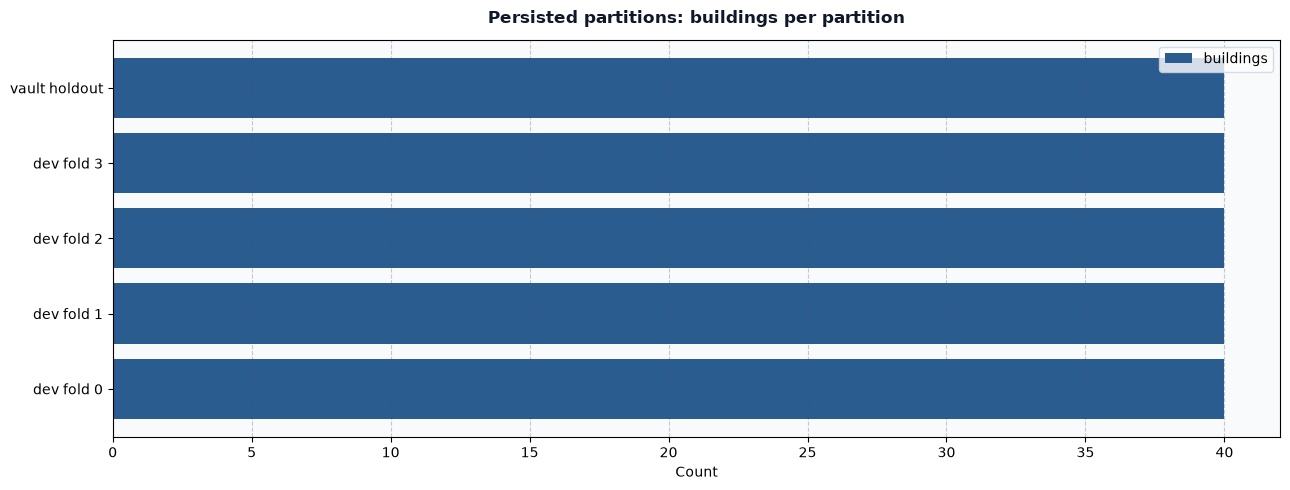

In [10]:
split_manifest = pl.read_parquet(split_path)
split_metadata = json.loads(split_metadata_path.read_text(encoding='utf-8'))
required_manifest_columns = {'building_id', 'split', 'fold', 'row_count', 'anomaly_count', 'normal_count'}
if not required_manifest_columns.issubset(split_manifest.columns):
    raise ValueError('Persisted building manifest is missing assignment or support fields')
is_repeated = 'repeat' in split_manifest.columns
if is_repeated:
    if split_manifest.select(['repeat', 'building_id']).is_duplicated().any():
        raise ValueError('Persisted repeated manifest contains duplicate building/repeat assignments')
    if split_manifest.get_column('building_id').n_unique() != 200:
        raise ValueError('Persisted manifest must cover 200 unique buildings')
else:
    if split_manifest.get_column('building_id').n_unique() != split_manifest.height:
        raise ValueError('Persisted manifest must contain one row per building')
manifest_hash = compute_file_sha256(split_path)
expected_hash = split_metadata.get('family_sha256') or split_metadata.get('artifacts', {}).get('building_folds_sha256')
if manifest_hash != expected_hash:
    raise ValueError('Persisted building manifest does not match its recorded hash')
training_buildings = set(train_joined.select('building_id').unique().collect(engine='streaming')
                         .get_column('building_id').to_list())
test_buildings = set(test_joined.select('building_id').unique().collect(engine='streaming')
                     .get_column('building_id').to_list())
manifest_buildings = set(split_manifest.get_column('building_id').to_list())
if manifest_buildings != training_buildings:
    raise ValueError('Persisted manifest does not cover current training buildings exactly')
if manifest_buildings.intersection(test_buildings):
    raise ValueError('A test building appears in the training split manifest')
single_rep = split_manifest.filter(pl.col('repeat') == 0) if is_repeated else split_manifest
partition_support = (single_rep.group_by(['split', 'fold'], maintain_order=True)
    .agg(pl.len().alias('buildings'), pl.col('row_count').sum().alias('rows'),
         pl.col('anomaly_count').sum().alias('anomaly_rows'),
         pl.col('normal_count').sum().alias('normal_rows'))
    .sort(['split', 'fold'], nulls_last=True))
if partition_support.filter((pl.col('anomaly_rows') == 0) | (pl.col('normal_rows') == 0)).height:
    raise ValueError('Every persisted partition must retain both target classes')
split_review = pl.DataFrame([{'manifest_buildings': split_manifest.get_column('building_id').n_unique(),
    'train_buildings_covered': len(training_buildings),
    'test_buildings_disjoint': not manifest_buildings.intersection(test_buildings),
    'repeats': split_metadata.get('repeats', 1),
    'split_seeds': str(split_metadata.get('split_seeds', [split_metadata.get('seed')])),
    'manifest_sha256_prefix': manifest_hash[:12]}])
display(split_review)
display(partition_support)

show_figure(plot_fold_composition(
    {(f"dev fold {row['fold']}" if row['split'] == 'dev' else 'vault holdout'):
        {'normal': int(row['normal_rows']), 'anomaly': int(row['anomaly_rows'])}
     for row in partition_support.to_dicts()},
    'Persisted partitions: observed-hour rows by class'))
show_figure(plot_comparative_count_bars(
    {(f"dev fold {row['fold']}" if row['split'] == 'dev' else 'vault holdout'):
        {'buildings': int(row['buildings'])}
     for row in partition_support.to_dicts()},
    'Persisted partitions: buildings per partition'))


**Observation:** The manifest summary and partition table are calculated from the current persisted assignment and training join.

**Interpretation:** Building-level assignment matches the unseen-building evaluation unit; it does not imply that a historical assignment is recoverable.

**Action:** Use this manifest as the fixed source for later validation. Do not replace it with a notebook-local split.

## Decisions for Notebook 02

### Decision ledger

| Decision | Current rule | Evidence boundary |
| --- | --- | --- |
| Problem formulation | Observed-hour point-anomaly classification | No future horizon is predicted |
| Target and primary metric | `anomaly`; ROC-AUC | Continuous scores preserve ranking |
| Grouping and validation | `building_id` is grouping-only; load the persisted manifest | Test buildings stay outside training folds |
| Feature provenance | `gte_*` is pending/blocked until verified | No name-based availability assumptions |
| Test-domain diagnostics | Shift diagnosis only | No test-guided feature selection or production-transform fitting |
| Data quality | Preserve labeled anomalies and unusual meter readings | No silent deletion or capping |
| Operational threshold | Not optimized | False-positive and false-negative costs are unspecified |

### Deferred experiments for Notebook 02

| Topic | Question to compare | Decision boundary |
| --- | --- | --- |
| Cleaning | Are any values demonstrable data defects? | Preserve rare and anomalous records unless a defect is verified |
| Missingness | Native missing values, imputation, and missingness indicators | Fit learned handling inside training folds |
| Preprocessing | Which model-specific transforms are needed? | Fit learned transforms on training folds only |
| Outlier policy | Retain raw readings versus a justified indicator or transform | Do not silently cap or delete; compare under fixed folds |
| Feature families and engineering | Which verified supplied or causal features add value? | Keep `gte_*` blocked until provenance and time availability are verified |
| PCA candidacy | Is a fold-local projection justified for a verified numeric block? | Compare with passthrough; do not assume dimensionality reduction helps |
| Imbalance | Do weighting or sampling alter ranking and guardrails? | Preserve ROC-AUC as primary; learned handling stays fold-local |

These are hypotheses for controlled comparisons, not conclusions about current data. Each applicable item should receive a finite experiment and an evidence-based outcome.

### Current evidence summary

The summary below is assembled from the target, quality, split, and domain-report values observed above.

### Outlier policy handoff note

Development partition profiling confirms extreme consumption ranges across buildings with no observation deleted or capped. Notebook 02 evaluates raw feature retention against fold-local robust transforms and exploratory indicator features under fixed cross-validation folds.

**Purpose:** Generate a concise reader-facing summary from the values in the current notebook run.

In [11]:
def interpret_domain_auc(domain_auc: float | None) -> str:
    if domain_auc is None:
        return 'The current domain ROC-AUC is not available in the persisted summary.'
    if not 0.0 <= domain_auc <= 1.0:
        raise ValueError('Domain ROC-AUC must be within [0, 1]')
    if domain_auc < 0.5:
        return ('Pooled OOF ROC-AUC is below 0.5 for positive class `test=1`, '
                'indicating an inverse ranking. Inspect class/score orientation and '
                'fold-level metrics; do not invert scores after seeing this result.')
    if domain_auc <= 0.55:
        return 'The current score is in the weak-separation heuristic band.'
    if domain_auc <= 0.60:
        return 'The current score is in the moderate-separation heuristic band.'
    return 'The current score indicates more material domain separation under the heuristic.'

auc_values = [row['value'] for row in domain_metrics.to_dicts()
              if row['metric'].casefold().endswith('pooled_oof.roc_auc')]
domain_auc = auc_values[0] if auc_values else None
shift_interpretation = interpret_domain_auc(domain_auc)
positive_prevalence = float(target_summary.filter(pl.col('anomaly') == 1)
                            .get_column('row_share').item())
true_constant_count = feature_quality.filter(pl.col('status') == 'true constant').height
quasi_constant_count = feature_quality.filter(pl.col('status') == 'quasi-constant').height
manifest_building_count = split_review.get_column('manifest_buildings').item()
manifest_hash_prefix = split_review.get_column('manifest_sha256_prefix').item()
report_text = (
    f'**Observation:** Current positive-row share is {positive_prevalence:.4%}; '
    f'{true_constant_count} true constants and {quasi_constant_count} quasi-constants '
    f'are flagged for review. The persisted manifest covers {manifest_building_count} '
    f'training buildings and has hash prefix `{manifest_hash_prefix}`.\n\n'
    f'**Interpretation:** {shift_interpretation}\n\n'
    '**Action:** Retain the persisted building split, keep unverified feature families blocked, '
    'and defer learned preprocessing, outlier policy, and feature decisions to fixed-fold comparisons.\n\n'
    '**Handoff to Notebook 02:** Outlier analysis confirmed heavy-tailed readings across development buildings; '
    'retain raw readings while comparing hypotheses for fold-local indicator flags and robust transforms under fixed folds.'
)
display(Markdown(report_text))

**Observation:** Current positive-row share is 2.1318%; 2 true constants and 0 quasi-constants are flagged for review. The persisted manifest covers 200 training buildings and has hash prefix `4b3433d604d7`.

**Interpretation:** Pooled OOF ROC-AUC is below 0.5 for positive class `test=1`, indicating an inverse ranking. Inspect class/score orientation and fold-level metrics; do not invert scores after seeing this result.

**Action:** Retain the persisted building split, keep unverified feature families blocked, and defer learned preprocessing, outlier policy, and feature decisions to fixed-fold comparisons.

**Handoff to Notebook 02:** Outlier analysis confirmed heavy-tailed readings across development buildings; retain raw readings while comparing hypotheses for fold-local indicator flags and robust transforms under fixed folds.